In [42]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
import numpy as np

In [43]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [44]:
# 데이터 전처리 완료
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight, random_state=1)
train_data


array([21. , 16.2, 24. , 43. , 28.7, 24.6, 39. , 43.5, 25. , 28. , 21.3,
       23. , 40. , 27.3, 22. , 42. , 27.5, 23.5, 17.4, 22. , 26.5, 25.6,
       40. , 36.5, 22. , 44. , 22.5, 24. , 18.7, 19. , 43. , 13.7, 22. ,
        8.4, 22. , 18. , 21. , 20. , 19.6, 21. , 37. , 32.8])

In [45]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
train_data[:3]

array([[21. ],
       [16.2],
       [24. ]])

In [46]:
# 데이터 학습
knr = KNeighborsRegressor()
knr.fit(train_data,train_label)

# 데이터 예측
predict = knr.predict(test_data)
# 정확도,오차
score = knr.score(train_data,train_label)
# ※ 회귀의 score는 정확도가 아니라 R²(1에 가까울수록 좋음)
score2 = knr.score(test_data,test_label)
print('정확도1:',score)
print('정확도2:',score2)

정확도1: 0.9899753375767333
정확도2: 0.9364645895704451


In [47]:
# 오차범위
mean = mean_absolute_error(test_label,predict)
# ※ 예측이 실제와 평균 몇 g 차이 나는지
print('오차범위(g):',mean)

오차범위(g): 57.32142857142858


100.0 [1040.]


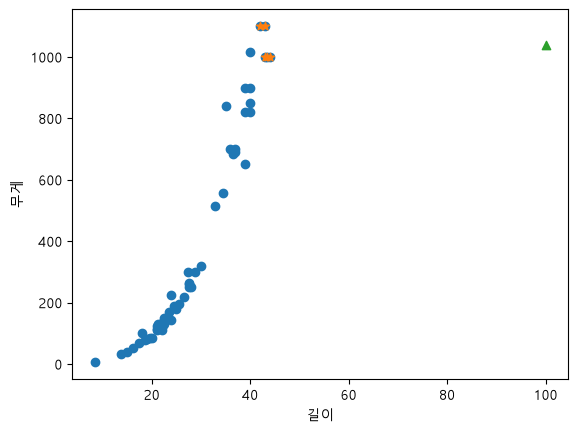

In [67]:
# 길이를 입력받아 무게를 예측하시오
l = input('길이:(예:27)') # 27:245
# 입력형태 : float,2차원배열[[]]
l = float(l)
w = knr.predict([[l]])
print(l,w)
distance, indexes = knr.kneighbors([[l]])
indexes
# 산점도 그래프
plt.scatter(perch_length,perch_weight)
plt.scatter(train_data[indexes],train_label[indexes],marker='*')
plt.scatter(l,w,marker='^')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()